## IMPORT LIBRARIES NEEDED AND GET DATA

In [147]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sklearn as sk
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
import optuna
from IPython.display import display

In [148]:
df = pd.read_csv('staten_island_data.csv')

In [149]:
display(df)

,address,zipCode,city,state,price,bed,bath,sqft,pricePerSf,lotArea,lotAreaType,zillowUrl,latitude,longitude,homeType,zestimate,rentZestimate,imageUrl
0,"40 Minna St, Staten Island, NY 10304",10304,Staten Island,NY,988000,4.0,3.0,2132.0,463.41,4356.00,sqft,https://zillow.com/homedetails/40-Minna-St-Sta...,40.593685,-74.091156,MULTI_FAMILY,986000.0,2955.0,https://photos.zillowstatic.com/fp/4690d1f0506...
1,"44 Annfield Ct, Staten Island, NY 10304",10304,Staten Island,NY,2399000,3.0,4.0,2700.0,888.52,0.28,acres,https://zillow.com/homedetails/44-Annfield-Ct-...,40.600510,-74.107056,SINGLE_FAMILY,2327600.0,4643.0,https://photos.zillowstatic.com/fp/2063264f277...
2,"74 Targee St, Staten Island, NY 10304",10304,Staten Island,NY,949900,3.0,3.0,2000.0,474.95,4791.60,sqft,https://zillow.com/homedetails/74-Targee-St-St...,40.625416,-74.083755,MULTI_FAMILY,914500.0,4057.0,https://photos.zillowstatic.com/fp/bce83737563...
3,"1150 Arthur Kill Rd, Staten Island, NY 10312",10312,Staten Island,NY,749000,3.0,2.0,884.0,847.29,3920.40,sqft,https://zillow.com/homedetails/1150-Arthur-Kil...,40.564300,-74.179570,SINGLE_FAMILY,746400.0,3438.0,https://photos.zillowstatic.com/fp/165a1461283...
4,"259 Seidman Ave, Staten Island, NY 10312",10312,Staten Island,NY,799999,4.0,2.0,1545.0,517.80,3920.40,sqft,https://zillow.com/homedetails/259-Seidman-Ave...,40.533962,-74.163270,SINGLE_FAMILY,839200.0,3094.0,https://photos.zillowstatic.com/fp/b73f46b40b7...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,"212 Lee Ave, Staten Island, NY 10307",10307,Staten Island,NY,699000,3.0,1.0,1235.0,565.99,4791.60,sqft,https://zillow.com/homedetails/212-Lee-Ave-Sta...,40.511818,-74.244260,SINGLE_FAMILY,692700.0,3084.0,https://photos.zillowstatic.com/fp/86cab5a2c4c...
476,"36 Sawyer Ave, Staten Island, NY 10314",10314,Staten Island,NY,918000,3.0,3.0,1216.0,754.93,4791.60,sqft,https://zillow.com/homedetails/36-Sawyer-Ave-S...,40.616955,-74.126520,SINGLE_FAMILY,904400.0,3441.0,https://photos.zillowstatic.com/fp/a9cc4e92f5e...
477,"146 Annadale Rd, Staten Island, NY 10312",10312,Staten Island,NY,599999,3.0,1.0,1216.0,493.42,3920.40,sqft,https://zillow.com/homedetails/146-Annadale-Rd...,40.560062,-74.177290,SINGLE_FAMILY,590600.0,2653.0,https://photos.zillowstatic.com/fp/8a526f995a2...
478,"911 Rathbun Ave, Staten Island, NY 10309",10309,Staten Island,NY,1328888,6.0,5.0,2900.0,458.24,3484.80,sqft,https://zillow.com/homedetails/911-Rathbun-Ave...,40.537167,-74.206180,MULTI_FAMILY,1316600.0,3551.0,https://photos.zillowstatic.com/fp/e3dfb962bfd...


In [150]:
display(df.head(50))

,address,zipCode,city,state,price,bed,bath,sqft,pricePerSf,lotArea,lotAreaType,zillowUrl,latitude,longitude,homeType,zestimate,rentZestimate,imageUrl
0,"40 Minna St, Staten Island, NY 10304",10304,Staten Island,NY,988000,4.0,3.0,2132.0,463.41,4356.00,sqft,https://zillow.com/homedetails/40-Minna-St-Sta...,40.593685,-74.091156,MULTI_FAMILY,986000.0,2955.0,https://photos.zillowstatic.com/fp/4690d1f0506...
1,"44 Annfield Ct, Staten Island, NY 10304",10304,Staten Island,NY,2399000,3.0,4.0,2700.0,888.52,0.28,acres,https://zillow.com/homedetails/44-Annfield-Ct-...,40.600510,-74.107056,SINGLE_FAMILY,2327600.0,4643.0,https://photos.zillowstatic.com/fp/2063264f277...
2,"74 Targee St, Staten Island, NY 10304",10304,Staten Island,NY,949900,3.0,3.0,2000.0,474.95,4791.60,sqft,https://zillow.com/homedetails/74-Targee-St-St...,40.625416,-74.083755,MULTI_FAMILY,914500.0,4057.0,https://photos.zillowstatic.com/fp/bce83737563...
3,"1150 Arthur Kill Rd, Staten Island, NY 10312",10312,Staten Island,NY,749000,3.0,2.0,884.0,847.29,3920.40,sqft,https://zillow.com/homedetails/1150-Arthur-Kil...,40.564300,-74.179570,SINGLE_FAMILY,746400.0,3438.0,https://photos.zillowstatic.com/fp/165a1461283...
4,"259 Seidman Ave, Staten Island, NY 10312",10312,Staten Island,NY,799999,4.0,2.0,1545.0,517.80,3920.40,sqft,https://zillow.com/homedetails/259-Seidman-Ave...,40.533962,-74.163270,SINGLE_FAMILY,839200.0,3094.0,https://photos.zillowstatic.com/fp/b73f46b40b7...
5,"45 Homestead Ave, Staten Island, NY 10302",10302,Staten Island,NY,599999,3.0,2.0,1336.0,449.10,4791.60,sqft,https://zillow.com/homedetails/45-Homestead-Av...,40.631380,-74.137570,SINGLE_FAMILY,613900.0,3309.0,https://photos.zillowstatic.com/fp/c82e17be64b...
6,"152 Durant Ave, Staten Island, NY 10306",10306,Staten Island,NY,769900,3.0,2.0,1232.0,624.92,2178.00,sqft,https://zillow.com/homedetails/152-Durant-Ave-...,40.555347,-74.132420,MULTI_FAMILY,765300.0,3310.0,https://photos.zillowstatic.com/fp/785c692f78d...
7,"459 Ridgewood Ave, Staten Island, NY 10312",10312,Staten Island,NY,699999,3.0,3.0,1280.0,546.87,2178.00,sqft,https://zillow.com/homedetails/459-Ridgewood-A...,40.559080,-74.165380,MULTI_FAMILY,712800.0,3501.0,https://photos.zillowstatic.com/fp/50bbc12e585...
8,"48 Covington Cir, Staten Island, NY 10312",10312,Staten Island,NY,1248000,4.0,4.0,2800.0,445.71,5662.80,sqft,https://zillow.com/homedetails/48-Covington-Ci...,40.546100,-74.204110,SINGLE_FAMILY,1252500.0,4460.0,https://photos.zillowstatic.com/fp/de72f473eff...
9,"220 Slater Blvd, Staten Island, NY 10305",10305,Staten Island,NY,799000,3.0,2.0,1872.0,426.82,6264.00,sqft,https://zillow.com/homedetails/220-Slater-Blvd...,40.579960,-74.088900,SINGLE_FAMILY,792200.0,3367.0,https://photos.zillowstatic.com/fp/adddff9441c...


In [151]:
df['lotAreaType'].value_counts()

lotAreaType
sqft     439
acres     30
Name: count, dtype: int64

In [152]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   address        480 non-null    object 
 1   zipCode        480 non-null    int64  
 2   city           480 non-null    object 
 3   state          480 non-null    object 
 4   price          480 non-null    int64  
 5   bed            478 non-null    float64
 6   bath           479 non-null    float64
 7   sqft           476 non-null    float64
 8   pricePerSf     476 non-null    float64
 9   lotArea        469 non-null    float64
 10  lotAreaType    469 non-null    object 
 11  zillowUrl      480 non-null    object 
 12  latitude       480 non-null    float64
 13  longitude      480 non-null    float64
 14  homeType       480 non-null    object 
 15  zestimate      400 non-null    float64
 16  rentZestimate  438 non-null    float64
 17  imageUrl       480 non-null    object 
dtypes: float64

## CLEAN UP DATA

In [153]:
df.loc[df['lotAreaType'] == 'acres', 'lotArea'] *= 43560
df['lotAreaType'] = 'sqft'

In [154]:
df.columns = (
    df.columns
    .str.strip()
    .str.upper()
)

In [155]:
df = df.drop(columns=['ADDRESS', 'CITY' ,'STATE', 'ZILLOWURL', 'ZESTIMATE', 'RENTZESTIMATE', 'IMAGEURL','PRICEPERSF'])

In [156]:
print(df['ZIPCODE'].nunique())

12


In [157]:
df.head(20)

,ZIPCODE,PRICE,BED,BATH,SQFT,LOTAREA,LOTAREATYPE,LATITUDE,LONGITUDE,HOMETYPE
0,10304,988000,4.0,3.0,2132.0,4356.0,sqft,40.593685,-74.091156,MULTI_FAMILY
1,10304,2399000,3.0,4.0,2700.0,12196.8,sqft,40.600510,-74.107056,SINGLE_FAMILY
2,10304,949900,3.0,3.0,2000.0,4791.6,sqft,40.625416,-74.083755,MULTI_FAMILY
3,10312,749000,3.0,2.0,884.0,3920.4,sqft,40.564300,-74.179570,SINGLE_FAMILY
4,10312,799999,4.0,2.0,1545.0,3920.4,sqft,40.533962,-74.163270,SINGLE_FAMILY
5,10302,599999,3.0,2.0,1336.0,4791.6,sqft,40.631380,-74.137570,SINGLE_FAMILY
6,10306,769900,3.0,2.0,1232.0,2178.0,sqft,40.555347,-74.132420,MULTI_FAMILY
7,10312,699999,3.0,3.0,1280.0,2178.0,sqft,40.559080,-74.165380,MULTI_FAMILY
8,10312,1248000,4.0,4.0,2800.0,5662.8,sqft,40.546100,-74.204110,SINGLE_FAMILY
9,10305,799000,3.0,2.0,1872.0,6264.0,sqft,40.579960,-74.088900,SINGLE_FAMILY


In [158]:
df.isna().sum()

ZIPCODE         0
PRICE           0
BED             2
BATH            1
SQFT            4
LOTAREA        11
LOTAREATYPE     0
LATITUDE        0
LONGITUDE       0
HOMETYPE        0
dtype: int64

In [159]:
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

cat_cols = df.select_dtypes(exclude=['number']).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [160]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ZIPCODE      480 non-null    int64  
 1   PRICE        480 non-null    int64  
 2   BED          480 non-null    float64
 3   BATH         480 non-null    float64
 4   SQFT         480 non-null    float64
 5   LOTAREA      480 non-null    float64
 6   LOTAREATYPE  480 non-null    object 
 7   LATITUDE     480 non-null    float64
 8   LONGITUDE    480 non-null    float64
 9   HOMETYPE     480 non-null    object 
dtypes: float64(6), int64(2), object(2)
memory usage: 37.6+ KB


In [161]:
df['HOMETYPE'] = df['HOMETYPE'].astype('category')

In [162]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   ZIPCODE      480 non-null    int64   
 1   PRICE        480 non-null    int64   
 2   BED          480 non-null    float64 
 3   BATH         480 non-null    float64 
 4   SQFT         480 non-null    float64 
 5   LOTAREA      480 non-null    float64 
 6   LOTAREATYPE  480 non-null    object  
 7   LATITUDE     480 non-null    float64 
 8   LONGITUDE    480 non-null    float64 
 9   HOMETYPE     480 non-null    category
dtypes: category(1), float64(6), int64(2), object(1)
memory usage: 34.6+ KB


In [163]:
df['BATHS_PER_BED'] = df['BATH'] / (df['BED'])
df["SQFT_X_BATH"] = df["SQFT"] * df["BATH"]
df["SQFT_PER_BATH"] = df["SQFT"] / (df["BATH"])
df["SQFT_PER_BED"] = df["SQFT"] / (df["BED"] )

In [164]:
display(df)

,ZIPCODE,PRICE,BED,BATH,SQFT,LOTAREA,LOTAREATYPE,LATITUDE,LONGITUDE,HOMETYPE,BATHS_PER_BED,SQFT_X_BATH,SQFT_PER_BATH,SQFT_PER_BED
0,10304,988000,4.0,3.0,2132.0,4356.0,sqft,40.593685,-74.091156,MULTI_FAMILY,0.750000,6396.0,710.666667,533.000000
1,10304,2399000,3.0,4.0,2700.0,12196.8,sqft,40.600510,-74.107056,SINGLE_FAMILY,1.333333,10800.0,675.000000,900.000000
2,10304,949900,3.0,3.0,2000.0,4791.6,sqft,40.625416,-74.083755,MULTI_FAMILY,1.000000,6000.0,666.666667,666.666667
3,10312,749000,3.0,2.0,884.0,3920.4,sqft,40.564300,-74.179570,SINGLE_FAMILY,0.666667,1768.0,442.000000,294.666667
4,10312,799999,4.0,2.0,1545.0,3920.4,sqft,40.533962,-74.163270,SINGLE_FAMILY,0.500000,3090.0,772.500000,386.250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,10307,699000,3.0,1.0,1235.0,4791.6,sqft,40.511818,-74.244260,SINGLE_FAMILY,0.333333,1235.0,1235.000000,411.666667
476,10314,918000,3.0,3.0,1216.0,4791.6,sqft,40.616955,-74.126520,SINGLE_FAMILY,1.000000,3648.0,405.333333,405.333333
477,10312,599999,3.0,1.0,1216.0,3920.4,sqft,40.560062,-74.177290,SINGLE_FAMILY,0.333333,1216.0,1216.000000,405.333333
478,10309,1328888,6.0,5.0,2900.0,3484.8,sqft,40.537167,-74.206180,MULTI_FAMILY,0.833333,14500.0,580.000000,483.333333


In [165]:
df['LOG_LOTAREA'] = np.log1p(df['LOTAREA'])

In [166]:
display(df)

,ZIPCODE,PRICE,BED,BATH,SQFT,LOTAREA,LOTAREATYPE,LATITUDE,LONGITUDE,HOMETYPE,BATHS_PER_BED,SQFT_X_BATH,SQFT_PER_BATH,SQFT_PER_BED,LOG_LOTAREA
0,10304,988000,4.0,3.0,2132.0,4356.0,sqft,40.593685,-74.091156,MULTI_FAMILY,0.750000,6396.0,710.666667,533.000000,8.379539
1,10304,2399000,3.0,4.0,2700.0,12196.8,sqft,40.600510,-74.107056,SINGLE_FAMILY,1.333333,10800.0,675.000000,900.000000,9.409011
2,10304,949900,3.0,3.0,2000.0,4791.6,sqft,40.625416,-74.083755,MULTI_FAMILY,1.000000,6000.0,666.666667,666.666667,8.474828
3,10312,749000,3.0,2.0,884.0,3920.4,sqft,40.564300,-74.179570,SINGLE_FAMILY,0.666667,1768.0,442.000000,294.666667,8.274204
4,10312,799999,4.0,2.0,1545.0,3920.4,sqft,40.533962,-74.163270,SINGLE_FAMILY,0.500000,3090.0,772.500000,386.250000,8.274204
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,10307,699000,3.0,1.0,1235.0,4791.6,sqft,40.511818,-74.244260,SINGLE_FAMILY,0.333333,1235.0,1235.000000,411.666667,8.474828
476,10314,918000,3.0,3.0,1216.0,4791.6,sqft,40.616955,-74.126520,SINGLE_FAMILY,1.000000,3648.0,405.333333,405.333333,8.474828
477,10312,599999,3.0,1.0,1216.0,3920.4,sqft,40.560062,-74.177290,SINGLE_FAMILY,0.333333,1216.0,1216.000000,405.333333,8.274204
478,10309,1328888,6.0,5.0,2900.0,3484.8,sqft,40.537167,-74.206180,MULTI_FAMILY,0.833333,14500.0,580.000000,483.333333,8.156453


## Test Train split

In [167]:
y = np.log1p(df['PRICE'])
X = df.drop(columns = ['PRICE','LOTAREATYPE','HOMETYPE'])


In [168]:
X

,ZIPCODE,BED,BATH,SQFT,LOTAREA,LATITUDE,LONGITUDE,BATHS_PER_BED,SQFT_X_BATH,SQFT_PER_BATH,SQFT_PER_BED,LOG_LOTAREA
0,10304,4.0,3.0,2132.0,4356.0,40.593685,-74.091156,0.750000,6396.0,710.666667,533.000000,8.379539
1,10304,3.0,4.0,2700.0,12196.8,40.600510,-74.107056,1.333333,10800.0,675.000000,900.000000,9.409011
2,10304,3.0,3.0,2000.0,4791.6,40.625416,-74.083755,1.000000,6000.0,666.666667,666.666667,8.474828
3,10312,3.0,2.0,884.0,3920.4,40.564300,-74.179570,0.666667,1768.0,442.000000,294.666667,8.274204
4,10312,4.0,2.0,1545.0,3920.4,40.533962,-74.163270,0.500000,3090.0,772.500000,386.250000,8.274204
...,...,...,...,...,...,...,...,...,...,...,...,...
475,10307,3.0,1.0,1235.0,4791.6,40.511818,-74.244260,0.333333,1235.0,1235.000000,411.666667,8.474828
476,10314,3.0,3.0,1216.0,4791.6,40.616955,-74.126520,1.000000,3648.0,405.333333,405.333333,8.474828
477,10312,3.0,1.0,1216.0,3920.4,40.560062,-74.177290,0.333333,1216.0,1216.000000,405.333333,8.274204
478,10309,6.0,5.0,2900.0,3484.8,40.537167,-74.206180,0.833333,14500.0,580.000000,483.333333,8.156453


In [169]:
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size = 0.2, random_state = 42)
zipcode_mean = (
    pd.DataFrame({
        'ZIPCODE': X_train['ZIPCODE'],
        'PRICE': y_train
    })
    .groupby('ZIPCODE')['PRICE']
    .mean()
)

global_mean = y_train.mean()

# Create encoded feature
X_train['ZIPCODE_TE'] = (
    X_train['ZIPCODE']
    .map(zipcode_mean)
    .fillna(global_mean)
)

X_test['ZIPCODE_TE'] = (
    X_test['ZIPCODE']
    .map(zipcode_mean)
    .fillna(global_mean)
)

print(X_train[['ZIPCODE', 'ZIPCODE_TE']].head(20))
# Remove original zipcode column
X_train = X_train.drop(columns=['ZIPCODE'])
X_test = X_test.drop(columns=['ZIPCODE'])



     ZIPCODE  ZIPCODE_TE
132    10303   13.066922
228    10302   13.469058
473    10314   13.521206
42     10306   13.711434
360    10314   13.521206
406    10307   13.907616
140    10306   13.711434
457    10312   13.711646
209    10301   13.714496
192    10306   13.711434
448    10305   13.564052
22     10304   13.761749
422    10307   13.907616
46     10314   13.521206
126    10305   13.564052
400    10314   13.521206
131    10305   13.564052
420    10314   13.521206
470    10306   13.711434
57     10306   13.711434


In [170]:
X_train

,BED,BATH,SQFT,LOTAREA,LATITUDE,LONGITUDE,BATHS_PER_BED,SQFT_X_BATH,SQFT_PER_BATH,SQFT_PER_BED,LOG_LOTAREA,ZIPCODE_TE
132,3.0,2.0,1568.5,3698.0,40.627117,-74.17930,0.666667,3137.0,784.250000,522.833333,8.215818,13.066922
228,4.0,4.0,2065.0,3712.0,40.639156,-74.13963,1.000000,8260.0,516.250000,516.250000,8.219595,13.469058
473,3.0,2.0,1320.0,880.0,40.608640,-74.16085,0.666667,2640.0,660.000000,440.000000,6.781058,13.521206
42,6.0,3.0,2032.0,4791.6,40.572426,-74.12047,0.500000,6096.0,677.333333,338.666667,8.474828,13.711434
360,4.0,3.0,2513.0,4100.0,40.587563,-74.15862,0.750000,7539.0,837.666667,628.250000,8.318986,13.521206
...,...,...,...,...,...,...,...,...,...,...,...,...
106,3.0,2.0,1188.0,3698.0,40.547180,-74.14292,0.666667,2376.0,594.000000,396.000000,8.215818,13.534770
270,5.0,3.0,2322.0,6098.4,40.534992,-74.21659,0.600000,6966.0,774.000000,464.400000,8.715946,13.786679
348,4.0,3.0,1551.0,4361.0,40.609913,-74.06001,0.750000,4653.0,517.000000,387.750000,8.380686,13.564052
435,4.0,2.0,1400.0,1742.4,40.550926,-74.21466,0.500000,2800.0,700.000000,350.000000,7.463593,13.786679


# Model testing time

## Linear regression

In [171]:
from sklearn.linear_model import LinearRegression

In [172]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [173]:
y_pred = model.predict(X_test)

Evaluate the performace of the model

In [174]:
r2 = sk.metrics.r2_score(y_test, y_pred) #variance of price (higher better)
mse = sk.metrics.mean_squared_error(y_test, y_pred) #average squared distance between predicted and actual value (lower is better)
mae = sk.metrics.mean_absolute_error(y_test, y_pred) # average abs distance betwween pred and actual value (lower is better)
intercept = model.intercept_ #y intercept of the regression line

print('r2 score: ', r2)
print('mean squared error: ', mse)
print('mean absolute error: ', mae)
print('intercept: ', intercept)

r2 score:  0.5160825063041334
mean squared error:  0.09521525741766323
mean absolute error:  0.17913737404191177
intercept:  166.33559269451519


<function matplotlib.pyplot.show(close=None, block=None)>

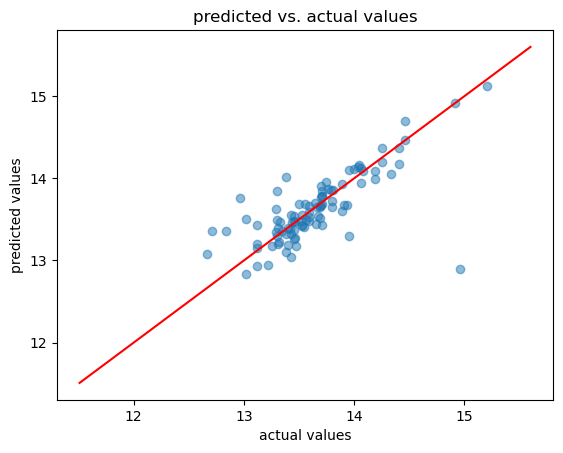

In [175]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = 'red')
plt.xlabel("actual values")
plt.ylabel('predicted values')
plt.title('predicted vs. actual values')
plt.show

If the model is a good fit, the points should be close to the diagonal line

Decision tree # supervised # classification tree/ regression tree can be used for both # doesnt require featurre scaling # better performance in nonlinear settings # prone to over fitting # small variation in data can change different tree # dont work well in hugly unbalanced classes # feature importance

## Decision tree

In [176]:
#bays opt
#obj function

def objective(trial):
    max_features_type = trial.suggest_categorical(
        "max_features_type",
        ["float", "sqrt", "log2"]
    )

    if max_features_type == "float":
        max_features = trial.suggest_float(
            "max_features_float",
            0.2,
            1.0
        )
    else:
        max_features = max_features_type
    params = {
        'max_depth': trial.suggest_int('max_depth',3,15),
        'min_samples_split': trial.suggest_int('min_samples_split',2,100),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf',1,100),
        'max_features': max_features
    }

    score = cross_val_score(
        sk.tree.DecisionTreeRegressor(**params),
        X_train,
        y_train,
        cv=5,
        scoring='r2'
    ).mean()
    
    return score

In [177]:
#run bays optmz
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials = 100)
print('Numbver opf finished trials:', len(study.trials))
print('Best trial:', study.best_trial.params)
print('Best accuracy:', study.best_trial.value)

[I 2026-11-07 18:22:15,239] A new study created in memory with name: no-name-2299903f-7cdd-4ce1-8362-454d6caba594
[I 2026-11-07 18:22:15,256] Trial 0 finished with value: 0.6049156261466991 and parameters: {'max_features_type': 'sqrt', 'max_depth': 14, 'min_samples_split': 47, 'min_samples_leaf': 21}. Best is trial 0 with value: 0.6049156261466991.
[I 2026-11-07 18:22:15,269] Trial 1 finished with value: 0.40077819572248413 and parameters: {'max_features_type': 'log2', 'max_depth': 11, 'min_samples_split': 46, 'min_samples_leaf': 64}. Best is trial 0 with value: 0.6049156261466991.
[I 2026-11-07 18:22:15,280] Trial 2 finished with value: 0.48000740427698385 and parameters: {'max_features_type': 'sqrt', 'max_depth': 15, 'min_samples_split': 87, 'min_samples_leaf': 8}. Best is trial 0 with value: 0.6049156261466991.
[I 2026-11-07 18:22:15,291] Trial 3 finished with value: 0.34760221124407414 and parameters: {'max_features_type': 'log2', 'max_depth': 3, 'min_samples_split': 64, 'min_sampl

Numbver opf finished trials: 100
Best trial: {'max_features_type': 'float', 'max_features_float': 0.9123217713891282, 'max_depth': 14, 'min_samples_split': 23, 'min_samples_leaf': 11}
Best accuracy: 0.6967411408012113


In [178]:
optuna.importance.get_param_importances(study)

{'min_samples_leaf': np.float64(0.9401154061408675),
 'min_samples_split': np.float64(0.029103487865691256),
 'max_features_type': np.float64(0.021585533152735245),
 'max_depth': np.float64(0.00919557284070589)}

In [179]:
print(study.best_params)
print(study.best_value)

{'max_features_type': 'float', 'max_features_float': 0.9123217713891282, 'max_depth': 14, 'min_samples_split': 23, 'min_samples_leaf': 11}
0.6967411408012113


In [180]:
best_params = study.best_trial.params.copy()

if best_params["max_features_type"] == "float":
    best_params["max_features"] = best_params["max_features_float"]
else:
    best_params["max_features"] = best_params["max_features_type"]

best_params.pop("max_features_type", None)
best_params.pop("max_features_float", None)

model = sk.tree.DecisionTreeRegressor(
    random_state=42,
    **best_params
)


model.fit(X_train, y_train)



DecisionTreeRegressor(max_depth=14, max_features=0.9123217713891282,
                      min_samples_leaf=11, min_samples_split=23,
                      random_state=42)

In [181]:
y_pred = model.predict(X_test)
print(model.score(X_test, y_test))

0.628187724657545


In [182]:
print("Best CV:", study.best_value)
print("Train :", model.score(X_train, y_train))
print("Test  :", model.score(X_test, y_test))

Best CV: 0.6967411408012113
Train : 0.8017067997219041
Test  : 0.628187724657545


Decision tree is high variance and is just a single tree, other models may peform better than decision tree in this case

In [186]:
r2 = sk.metrics.r2_score(y_test, y_pred) #variance of price (higher better)
mse = sk.metrics.mean_squared_error(y_test, y_pred) #average squared distance between predicted and actual value (lower is better)
mae = sk.metrics.mean_absolute_error(y_test, y_pred) # average abs distance betwween pred and actual value (lower is better)


print('r2 score: ', r2)
print('mean squared error: ', mse)
print('mean absolute error: ', mae)

r2 score:  0.628187724657545
mean squared error:  0.0731575154214792
mean absolute error:  0.1986149785440472


<function matplotlib.pyplot.show(close=None, block=None)>

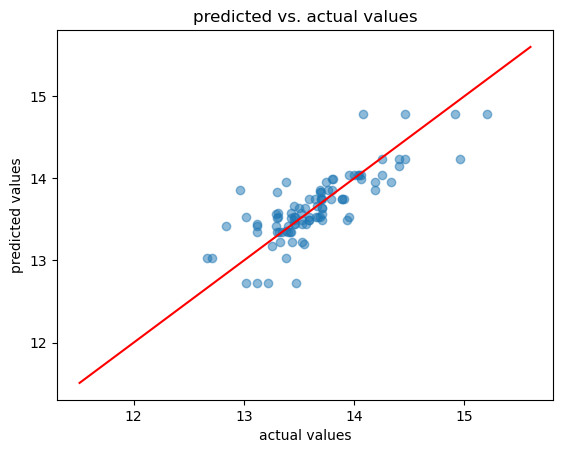

In [187]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = 'red')
plt.xlabel("actual values")
plt.ylabel('predicted values')
plt.title('predicted vs. actual values')
plt.show

In [188]:
sk.model_selection.cross_val_score(model, X,y, cv =5, scoring = 'r2').mean()

np.float64(0.6204402711023072)

Random forest time # pick random k data points fomr training sets # build decision tree associated to those k data points #keep doing the first two hashtags for the N trees you want to build. avg it out to get better predictions that decision treeregressor

# Random forest

In [189]:
#bays opt
#obj function

def objective(trial):
    max_features_type = trial.suggest_categorical(
        "max_features_type",
        ["float", "sqrt", "log2"]
    )
    
    if max_features_type == "float":
        max_features = trial.suggest_float(
            "max_features_float",
            0.2,
            1.0
        )
    else:
        max_features = max_features_type
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200,1000, step=1),
        'max_depth': trial.suggest_int('max_depth',3,15),
        'min_samples_split': trial.suggest_int('min_samples_split',2,50),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf',1,50),
        'max_features': max_features
    }

    model = sk.ensemble.RandomForestRegressor(random_state = 42, **params)
    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='r2',
        n_jobs=-1
    ).mean()

    return score

In [190]:
#run bays optmz
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials = 200)
print('Numbver opf finished trials:', len(study.trials))
print('Best trial:', study.best_trial.params)
print('Best accuracy:', study.best_trial.value)

[I 2026-11-07 18:22:17,516] A new study created in memory with name: no-name-38b8cb8c-13b7-4f0b-bfdc-c95dc950122b
[I 2026-11-07 18:22:19,658] Trial 0 finished with value: 0.5313725939855967 and parameters: {'max_features_type': 'sqrt', 'n_estimators': 329, 'max_depth': 13, 'min_samples_split': 10, 'min_samples_leaf': 48}. Best is trial 0 with value: 0.5313725939855967.
[I 2026-11-07 18:22:21,569] Trial 1 finished with value: 0.6687685314143097 and parameters: {'max_features_type': 'sqrt', 'n_estimators': 849, 'max_depth': 10, 'min_samples_split': 50, 'min_samples_leaf': 19}. Best is trial 1 with value: 0.6687685314143097.
[I 2026-11-07 18:22:23,322] Trial 2 finished with value: 0.5354334305438223 and parameters: {'max_features_type': 'log2', 'n_estimators': 805, 'max_depth': 4, 'min_samples_split': 32, 'min_samples_leaf': 48}. Best is trial 1 with value: 0.6687685314143097.
[I 2026-11-07 18:22:23,962] Trial 3 finished with value: 0.5898411476587401 and parameters: {'max_features_type':

Numbver opf finished trials: 200
Best trial: {'max_features_type': 'log2', 'n_estimators': 501, 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1}
Best accuracy: 0.7640521077112296


In [191]:
optuna.importance.get_param_importances(study)

{'min_samples_leaf': np.float64(0.994090761800671),
 'min_samples_split': np.float64(0.0022582116185905134),
 'n_estimators': np.float64(0.0018644429588353256),
 'max_features_type': np.float64(0.001146134445690441),
 'max_depth': np.float64(0.0006404491762126368)}

In [192]:
print(study.best_params)
print(study.best_value)

{'max_features_type': 'log2', 'n_estimators': 501, 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1}
0.7640521077112296


In [193]:
best_params = study.best_trial.params
best_params = study.best_trial.params.copy()

if best_params["max_features_type"] == "int":
    best_params["max_features"] = best_params["max_features_int"]

elif best_params["max_features_type"] == "float":
    best_params["max_features"] = best_params["max_features_float"]

else:
    best_params["max_features"] = best_params["max_features_type"]

# Remove Optuna-only parameters
best_params.pop("max_features_type", None)
best_params.pop("max_features_int", None)
best_params.pop("max_features_float", None)

rand_model = sk.ensemble.RandomForestRegressor(random_state =42, **best_params)
rand_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=12, max_features='log2', n_estimators=501,
                      random_state=42)

In [194]:
y_pred = rand_model.predict(X_test)
rand_model.score(X_test, y_test)

0.7164107955167829

In [195]:
print("Best CV:", study.best_value)
print("Train :", rand_model.score(X_train, y_train))
print("Test  :", rand_model.score(X_test, y_test))

Best CV: 0.7640521077112296
Train : 0.9638450216065014
Test  : 0.7164107955167829


In [196]:
r2 = sk.metrics.r2_score(y_test, y_pred) #variance of price (higher better)
mse = sk.metrics.mean_squared_error(y_test, y_pred) #average squared distance between predicted and actual value (lower is better)
mae = sk.metrics.mean_absolute_error(y_test, y_pred) # average abs distance betwween pred and actual value (lower is better)


print('r2 score: ', r2)
print('mean squared error: ', mse)
print('mean absolute error: ', mae)



r2 score:  0.7164107955167829
mean squared error:  0.05579880756017911
mean absolute error:  0.15324968717221882


<function matplotlib.pyplot.show(close=None, block=None)>

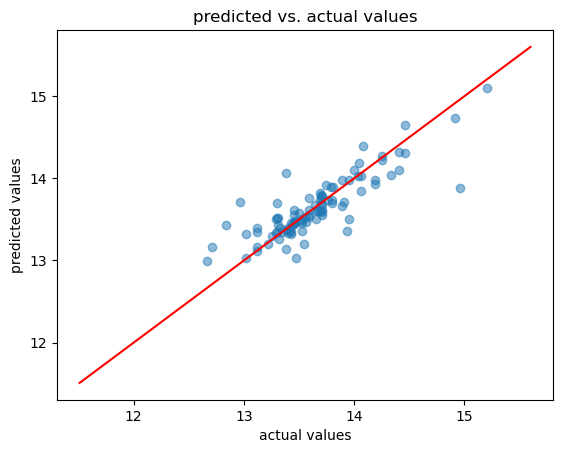

In [197]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = 'red')
plt.xlabel("actual values")
plt.ylabel('predicted values')
plt.title('predicted vs. actual values')
plt.show

## EXTRA tree regressor

In [198]:
#bays opt
#obj function

def objective(trial):
    max_features_type = trial.suggest_categorical(
        "max_features_type",
        ["float", "sqrt", "log2"]
    )
    
    if max_features_type == "float":
        max_features = trial.suggest_float(
            "max_features_float",
            0.2,
            1.0
        )
    else:
        max_features = max_features_type
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 500,2000, step=1),
        'max_depth': trial.suggest_int('max_depth',10,50),
        'min_samples_split': trial.suggest_int('min_samples_split',2,20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf',1,10),
        'max_features': max_features
    }

    model = sk.ensemble.ExtraTreesRegressor(random_state = 42, **params)
    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='r2',
        n_jobs=-1
    ).mean()
    
    return score

In [199]:
#run bays optmz
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials = 200)
print('Numbver opf finished trials:', len(study.trials))
print('Best trial:', study.best_trial.params)
print('Best accuracy:', study.best_trial.value)

[I 2026-11-07 18:24:14,817] A new study created in memory with name: no-name-69cffb48-cf7f-4c60-96be-eeae77ccfc56
[I 2026-11-07 18:24:15,427] Trial 0 finished with value: 0.6350655749195049 and parameters: {'max_features_type': 'float', 'max_features_float': 0.28363868742295956, 'n_estimators': 1236, 'max_depth': 10, 'min_samples_split': 18, 'min_samples_leaf': 7}. Best is trial 0 with value: 0.6350655749195049.
[I 2026-11-07 18:24:16,185] Trial 1 finished with value: 0.7481587306604458 and parameters: {'max_features_type': 'sqrt', 'n_estimators': 1330, 'max_depth': 21, 'min_samples_split': 10, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.7481587306604458.
[I 2026-11-07 18:24:16,784] Trial 2 finished with value: 0.724090363118827 and parameters: {'max_features_type': 'log2', 'n_estimators': 1129, 'max_depth': 46, 'min_samples_split': 15, 'min_samples_leaf': 3}. Best is trial 1 with value: 0.7481587306604458.
[I 2026-11-07 18:24:17,474] Trial 3 finished with value: 0.7559004277

Numbver opf finished trials: 200
Best trial: {'max_features_type': 'sqrt', 'n_estimators': 1233, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 1}
Best accuracy: 0.7685335370526227


In [200]:
optuna.importance.get_param_importances(study)

{'min_samples_leaf': np.float64(0.8838423709897202),
 'min_samples_split': np.float64(0.05199605214348486),
 'max_depth': np.float64(0.03933484395225803),
 'n_estimators': np.float64(0.014472101419401074),
 'max_features_type': np.float64(0.010354631495135937)}

In [201]:
best_params = study.best_trial.params
best_params = study.best_trial.params.copy()

if best_params["max_features_type"] == "int":
    best_params["max_features"] = best_params["max_features_int"]

elif best_params["max_features_type"] == "float":
    best_params["max_features"] = best_params["max_features_float"]

else:
    best_params["max_features"] = best_params["max_features_type"]

# Remove Optuna-only parameters
best_params.pop("max_features_type", None)
best_params.pop("max_features_int", None)
best_params.pop("max_features_float", None)
new_new_model = sk.ensemble.ExtraTreesRegressor(random_state =42, **best_params)
new_new_model.fit(X_train, y_train)

ExtraTreesRegressor(max_depth=16, max_features='sqrt', n_estimators=1233,
                    random_state=42)

In [202]:
y_pred = new_new_model.predict(X_test)
new_new_model.score(X_test, y_test)

0.7021570328510116

In [203]:
from sklearn.metrics import r2_score

train_pred = new_new_model.predict(X_train)
test_pred = new_new_model.predict(X_test)

print("Train:", r2_score(y_train, train_pred))
print("Test :", r2_score(y_test, test_pred))

Train: 0.9968236704143575
Test : 0.7021570328510116


In [204]:
r2 = sk.metrics.r2_score(y_test, y_pred) #variance of price (higher better)
mse = sk.metrics.mean_squared_error(y_test, y_pred) #average squared distance between predicted and actual value (lower is better)
mae = sk.metrics.mean_absolute_error(y_test, y_pred) # average abs distance betwween pred and actual value (lower is better)


print('r2 score: ', r2)
print('mean squared error: ', mse)
print('mean absolute error: ', mae)

r2 score:  0.7021570328510116
mean squared error:  0.05860336763306759
mean absolute error:  0.15941325388880415


In [205]:
import pandas as pd

imp = pd.Series(
    new_new_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(imp.head(20))

BATHS_PER_BED    0.185593
BED              0.172948
BATH             0.162019
SQFT_PER_BED     0.100606
ZIPCODE          0.097606
SQFT             0.062826
SQFT_PER_BATH    0.051907
SQFT_X_BATH      0.039577
LOG_LOTAREA      0.037290
LOTAREA          0.032479
LONGITUDE        0.031892
LATITUDE         0.025257
dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

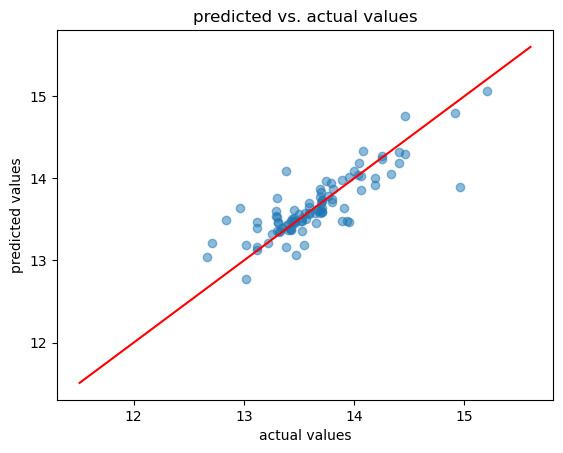

In [206]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = 'red')
plt.xlabel("actual values")
plt.ylabel('predicted values')
plt.title('predicted vs. actual values')
plt.show

XGBoost Regression # gradient boosting ??? #iterating decision trees, learning from past tress # cutsom objective function with loss func bewteen predicted and acutal values and a regularization term to controll complexity and overfittting # gradient descent for each tree is to reduce residuals# tree pruning tech stops splitting early when improvement is marginal (less complex model overfiting)

## XGBoost regression

In [207]:
pred = new_new_model.predict(X_test)

errors = y_test - pred

print(errors.describe())

count    96.000000
mean     -0.009432
std       0.243167
min      -0.705142
25%      -0.088294
50%      -0.012574
75%       0.081530
max       1.068995
Name: PRICE, dtype: float64


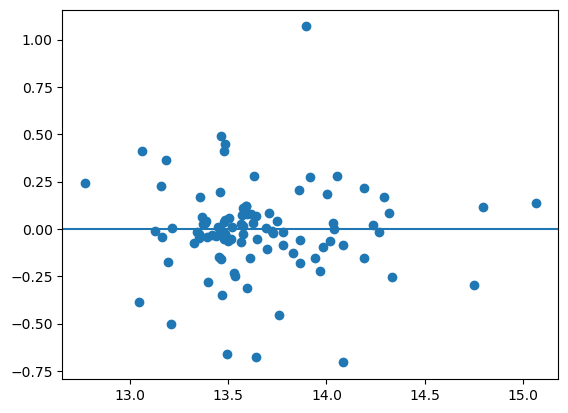

In [208]:
plt.scatter(pred, errors)
plt.axhline(0)

In [209]:
from xgboost import XGBRegressor

In [210]:
#bays opt
#obj function

from xgboost import XGBRegressor

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 2000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", .1, 1.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 10.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 20.0)
    }

    model = XGBRegressor(**params)

    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    ).mean()

    return score

In [211]:
#run bays optmz
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials = 200)
print('Numbver opf finished trials:', len(study.trials))
print('Best trial:', study.best_trial.params)
print('Best accuracy:', study.best_trial.value)

[I 2026-11-07 18:27:21,194] A new study created in memory with name: no-name-62499361-bfb6-4c0f-a095-7d844513225e
[I 2026-11-07 18:27:22,044] Trial 0 finished with value: 0.642687626923694 and parameters: {'n_estimators': 2000, 'learning_rate': 0.1297249031029463, 'max_depth': 5, 'min_child_weight': 6, 'subsample': 0.8175479253200317, 'colsample_bytree': 0.7324014148939951, 'gamma': 1.4127292658735287, 'reg_alpha': 1.6840293546604401, 'reg_lambda': 14.735520148002108}. Best is trial 0 with value: 0.642687626923694.
[I 2026-11-07 18:27:22,232] Trial 1 finished with value: 0.5045709453391394 and parameters: {'n_estimators': 300, 'learning_rate': 0.01486904435757032, 'max_depth': 5, 'min_child_weight': 8, 'subsample': 0.7183328255990155, 'colsample_bytree': 0.890772213425931, 'gamma': 0.4421579991537734, 'reg_alpha': 9.045469544787139, 'reg_lambda': 18.37746071087431}. Best is trial 0 with value: 0.642687626923694.
[I 2026-11-07 18:27:22,431] Trial 2 finished with value: 0.498304387226196

Numbver opf finished trials: 200
Best trial: {'n_estimators': 800, 'learning_rate': 0.059446843954300076, 'max_depth': 5, 'min_child_weight': 7, 'subsample': 0.7863323912703105, 'colsample_bytree': 0.840661234417537, 'gamma': 0.14150974613795583, 'reg_alpha': 0.0007396075064056949, 'reg_lambda': 3.460113884884157}
Best accuracy: 0.7513666369313607


In [212]:
optuna.importance.get_param_importances(study)

{'reg_alpha': np.float64(0.8248622809272715),
 'gamma': np.float64(0.05441198341718851),
 'reg_lambda': np.float64(0.048284439291156236),
 'max_depth': np.float64(0.023121545677563624),
 'colsample_bytree': np.float64(0.017972463393263496),
 'n_estimators': np.float64(0.01726118900312217),
 'learning_rate': np.float64(0.0069889324778039255),
 'min_child_weight': np.float64(0.005491776849844035),
 'subsample': np.float64(0.001605388962786433)}

In [213]:
print(study.best_params)
print(study.best_value)

{'n_estimators': 800, 'learning_rate': 0.059446843954300076, 'max_depth': 5, 'min_child_weight': 7, 'subsample': 0.7863323912703105, 'colsample_bytree': 0.840661234417537, 'gamma': 0.14150974613795583, 'reg_alpha': 0.0007396075064056949, 'reg_lambda': 3.460113884884157}
0.7513666369313607


In [214]:
best_params = study.best_trial.params
xmodel = XGBRegressor(random_state =42, **best_params)
xmodel.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.840661234417537, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.14150974613795583, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.059446843954300076,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=7, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=800, n_jobs=None,
             num_parallel_tree=None, ...)

In [215]:
y_pred = xmodel.predict(X_test)
xmodel.score(X_test, y_test)

0.7162587175262315

In [216]:
print("Train:", xmodel.score(X_train, y_train))
print("Test :", xmodel.score(X_test, y_test))

Train: 0.896123480635447
Test : 0.7162587175262315


In [217]:
imp = pd.Series(
    xmodel.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(imp.head(20))

SQFT             0.205866
SQFT_X_BATH      0.200065
BED              0.199236
BATH             0.077445
LOTAREA          0.075993
LOG_LOTAREA      0.054502
SQFT_PER_BED     0.040133
LATITUDE         0.031745
BATHS_PER_BED    0.030320
ZIPCODE_TE       0.030319
LONGITUDE        0.027790
SQFT_PER_BATH    0.026585
dtype: float32


In [218]:
r2 = sk.metrics.r2_score(y_test, y_pred) #variance of price (higher better)
mse = sk.metrics.mean_squared_error(y_test, y_pred) #average squared distance between predicted and actual value (lower is better)
mae = sk.metrics.mean_absolute_error(y_test, y_pred) # average abs distance betwween pred and actual value (lower is better)


print('r2 score: ', r2)
print('mean squared error: ', mse)
print('mean absolute error: ', mae)

r2 score:  0.7162587175262315
mean squared error:  0.055828730316034296
mean absolute error:  0.16111734689372167


<function matplotlib.pyplot.show(close=None, block=None)>

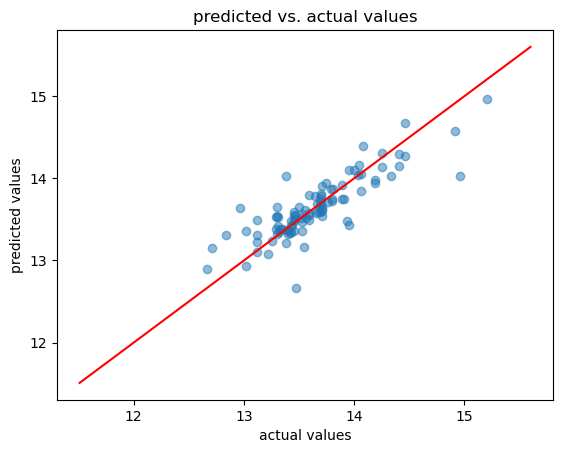

In [219]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = 'red')
plt.xlabel("actual values")
plt.ylabel('predicted values')
plt.title('predicted vs. actual values')
plt.show

## Linear regression
r2 score:  0.5160825063041334   
mean squared error:  0.09521525741766323   
mean absolute error:  0.17913737404191177   

## Decision tree regressor
r2 score:  0.668414217515785   
mean squared error:  0.06524257966816603   
mean absolute error:  0.1851209579818586   

## Random forest regressor
r2 score:  0.7169118642442502   
mean squared error:  0.05570021763836131   
mean absolute error:  0.15207822156721074   

## Extra trees regressor
r2 score:  0.7125168049131344   
mean squared error:  0.056564986345898675   
mean absolute error:  0.15621013819063784   

## XGBRegressor
r2 score:  0.7092168560853034   
mean squared error:  0.05721428189979019   
mean absolute error:  0.16225327904189765  

## results

Linear Regression achieved an r2 score of 0.516, meaning it explains approximately 51.6% of the variation in home prices. This is expected since linear regression assumes a linear relationship between property features and prices, whereas housing prices are influenced by many complex factors. It serves as a good baseline model for comparison.

The Decision Tree achieved an r2 score of 0.668, showing a significant improvement over linear regression. This is because decision trees can capture nonlinear relationships between features, such as how location and square footage influence property prices. However, its MAE is slightly higher than linear regression.

Random Forest achieved the highest r2 score of 0.717, along with the lowest MSE and MAE. By combining multiple decision trees, it can capture complex patterns while reducing the risk of overfitting. Based on these results, it is the best-performing model.

Extra Trees achieved an r2 score of 0.713, performing very similarly to Random Forest. It also uses multiple decision trees but introduces additional randomness when creating them. Although its performance is strong, it is slightly less accurate than Random Forest across all three metrics.

XGBoost achieved an r2 score of 0.709, making it another strong model. It builds decision trees sequentially, with each tree attempting to correct errors made by previous trees. While it performs better than Linear Regression and a standard Decision Tree, it falls slightly behind Random Forest and Extra Trees.

Overall, Random Forest performed the best, achieving the highest r2 and lowest MSE and MAE.